# 02. Feature Engineering (v6 - Policy-based Pre-training)

**목적**: 그룹 단위 주간 목표 추천을 위한 정책 기반 학습 데이터 생성

**핵심 변경 사항 (v6)**:
- ✅ 7개 Feature (기존 12개 → 7개로 축소)
- ✅ 개인 추세 Feature 제거 (정책 기반 접근)
- ✅ 3주 롤링 통계 추가 (trend, level, stability)
- ✅ Policy-based Target: `recommended_growth_rate` (0.95~1.10)
- ❌ season 제거
- ❌ 개인별 성장률, 달성률, 추세 제거

**출력**: 4개 CSV 파일 (각 8 columns: 7 features + 1 target)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# 스타일 설정
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


## Step 1: 데이터 로드 및 전처리

In [2]:
# 원본 데이터 로드
df = pd.read_csv('../data/raw/health_fitness_dataset.csv')

print(f"원본 데이터: {df.shape}")
print(f"\n컬럼 목록:")
print(df.columns.tolist())

df.head()

원본 데이터: (687701, 22)

컬럼 목록:
['participant_id', 'date', 'age', 'gender', 'height_cm', 'weight_kg', 'activity_type', 'duration_minutes', 'intensity', 'calories_burned', 'avg_heart_rate', 'hours_sleep', 'stress_level', 'daily_steps', 'hydration_level', 'bmi', 'resting_heart_rate', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'health_condition', 'smoking_status', 'fitness_level']


,participant_id,date,age,gender,height_cm,weight_kg,activity_type,duration_minutes,intensity,calories_burned,...,stress_level,daily_steps,hydration_level,bmi,resting_heart_rate,blood_pressure_systolic,blood_pressure_diastolic,health_condition,smoking_status,fitness_level
0,1,2024-01-01,56,F,165.3,53.7,Dancing,41,Low,3.3,...,3,7128,1.5,19.6,69.5,110.7,72.9,NaN,Never,0.04
1,1,2024-01-04,56,F,165.3,53.9,Swimming,28,Low,2.9,...,7,7925,1.8,19.6,69.5,110.7,72.9,NaN,Never,0.07
2,1,2024-01-05,56,F,165.3,54.2,Swimming,21,Medium,2.6,...,7,7557,2.7,19.6,69.5,110.7,72.9,NaN,Never,0.09
3,1,2024-01-07,56,F,165.3,54.4,Weight Training,99,Medium,10.7,...,8,11120,2.6,19.6,69.5,110.7,72.9,NaN,Never,0.21
4,1,2024-01-09,56,F,165.3,54.7,Swimming,100,Medium,12.7,...,1,5406,1.5,19.6,69.5,110.7,72.9,NaN,Never,0.33


In [3]:
# v6: 필요한 컬럼만 선택
keep_cols = [
    'participant_id',
    'date',
    'age',
    'bmi',
    'daily_steps',
    'calories_burned',
    'duration_minutes',
    'fitness_level'
]

df = df[keep_cols].copy()

# 날짜 변환
df['date'] = pd.to_datetime(df['date'])

# distance_km 계산 (평균 보폭 0.75m 기준)
# 걸음수 * 0.00075 = km
df['distance_km'] = df['daily_steps'] * 0.00075

# 결측치 제거
df = df.dropna()

print(f"전처리 후 데이터: {df.shape}")
print(f"\n유지된 컬럼 ({len(keep_cols)}개):")
for col in keep_cols:
    print(f"  - {col}")
print(f"\n생성된 컬럼:")
print(f"  - distance_km (= daily_steps * 0.00075)")
print(f"\n최종 컬럼 수: {len(df.columns)}개")

df.head()

전처리 후 데이터: (687701, 9)

유지된 컬럼 (8개):
  - participant_id
  - date
  - age
  - bmi
  - daily_steps
  - calories_burned
  - duration_minutes
  - fitness_level

생성된 컬럼:
  - distance_km (= daily_steps * 0.00075)

최종 컬럼 수: 9개


,participant_id,date,age,bmi,daily_steps,calories_burned,duration_minutes,fitness_level,distance_km
0,1,2024-01-01,56,19.6,7128,3.3,41,0.04,5.34600
1,1,2024-01-04,56,19.6,7925,2.9,28,0.07,5.94375
2,1,2024-01-05,56,19.6,7557,2.6,21,0.09,5.66775
3,1,2024-01-07,56,19.6,11120,10.7,99,0.21,8.34000
4,1,2024-01-09,56,19.6,5406,12.7,100,0.33,4.05450


## Step 2: 그룹 생성 (fitness_level 기준)

In [4]:
# fitness_level 계산 (없는 경우)
if 'fitness_level' not in df.columns or df['fitness_level'].isna().all():
    # 간단한 fitness_level 계산: 평균 걸음수 기준
    participant_avg_steps = df.groupby('participant_id')['daily_steps'].mean()
    
    def assign_fitness_level(avg_steps):
        if avg_steps < 5000:
            return 1
        elif avg_steps < 7500:
            return 2
        elif avg_steps < 10000:
            return 3
        else:
            return 4
    
    fitness_map = participant_avg_steps.apply(assign_fitness_level)
    df['fitness_level'] = df['participant_id'].map(fitness_map)

# 참가자별 fitness_level로 정렬
participants = df[['participant_id', 'fitness_level']].drop_duplicates().sort_values('fitness_level')

# 2-6명 랜덤 크기 그룹 생성
np.random.seed(42)
groups = []
current_group = []
group_id = 1

for pid in participants['participant_id']:
    current_group.append(pid)
    
    # 그룹 크기: 2-6명 랜덤
    if len(current_group) >= np.random.randint(2, 7):
        for member in current_group:
            groups.append({'participant_id': member, 'group_id': group_id})
        group_id += 1
        current_group = []

# 남은 참가자 처리
if current_group:
    for member in current_group:
        groups.append({'participant_id': member, 'group_id': group_id})

group_df = pd.DataFrame(groups)
df = df.merge(group_df, on='participant_id', how='left')

print(f"✅ 그룹 생성 완료")
print(f"  - 총 그룹 수: {df['group_id'].nunique()}")
print(f"  - 그룹당 평균 인원: {df.groupby('group_id')['participant_id'].nunique().mean():.1f}명")

# 그룹별 인원 분포
group_sizes = df.groupby('group_id')['participant_id'].nunique()
print(f"\n그룹 크기 분포:")
print(group_sizes.value_counts().sort_index())

✅ 그룹 생성 완료
  - 총 그룹 수: 195821
  - 그룹당 평균 인원: 3.5명

그룹 크기 분포:
participant_id
2    38921
3    63060
4    56143
5    30075
6     7622
Name: count, dtype: int64


## Step 3: 주차별 그룹 집계

In [5]:
# 주차 계산 (월요일 시작)
df['week'] = df['date'].dt.to_period('W-MON')

# 주차별 그룹 집계
weekly_group = df.groupby(['group_id', 'week']).agg({
    'participant_id': 'nunique',  # member_count
    'age': 'mean',                 # avg_age
    'bmi': 'mean',                 # avg_bmi
    'daily_steps': 'sum',          # group_steps_total
    'calories_burned': 'sum',      # group_kcal_total
    'duration_minutes': 'sum',     # group_duration_total
    'distance_km': 'sum'           # group_distance_total
}).reset_index()

# 컬럼명 변경
weekly_group.rename(columns={
    'participant_id': 'member_count',
    'age': 'avg_age',
    'bmi': 'avg_bmi',
    'daily_steps': 'group_steps_total',
    'calories_burned': 'group_kcal_total',
    'duration_minutes': 'group_duration_total',
    'distance_km': 'group_distance_total'
}, inplace=True)

# week를 timestamp로 변환 (정렬용)
weekly_group['week_start'] = weekly_group['week'].dt.start_time
weekly_group = weekly_group.sort_values(['group_id', 'week_start'])

print(f"✅ 주차별 집계 완료")
print(f"  - 총 레코드: {len(weekly_group)}")
print(f"  - 주차 범위: {weekly_group['week'].min()} ~ {weekly_group['week'].max()}")

weekly_group.head(10)

✅ 주차별 집계 완료
  - 총 레코드: 10368298
  - 주차 범위: 2023-12-26/2024-01-01 ~ 2024-12-24/2024-12-30


,group_id,week,member_count,avg_age,avg_bmi,group_steps_total,group_kcal_total,group_duration_total,group_distance_total,week_start
0,1,2023-12-26/2024-01-01,4,47.500000,19.875000,29629,13.5,87,22.22175,2023-12-26
1,1,2024-01-02/2024-01-08,6,47.714286,21.160714,251750,341.7,1895,188.81250,2024-01-02
2,1,2024-01-09/2024-01-15,6,47.500000,20.826923,240015,283.6,1676,180.01125,2024-01-09
3,1,2024-01-16/2024-01-22,6,47.115385,21.400000,236105,325.4,2010,177.07875,2024-01-16
4,1,2024-01-23/2024-01-29,6,47.722222,21.122222,333785,445.9,2861,250.33875,2024-01-23
5,1,2024-01-30/2024-02-05,6,45.375000,21.021875,302403,362.8,2158,226.80225,2024-01-30
6,1,2024-02-06/2024-02-12,6,42.777778,21.044444,256231,407.1,2242,192.17325,2024-02-06
7,1,2024-02-13/2024-02-19,6,44.766667,21.180000,280918,415.0,2272,210.68850,2024-02-13
8,1,2024-02-20/2024-02-26,6,47.866667,20.820000,278238,403.4,1905,208.67850,2024-02-20
9,1,2024-02-27/2024-03-04,6,45.400000,21.183333,294841,395.9,1889,221.13075,2024-02-27


## Step 4: 구성원 간 편차 계산 (member_steps_var)

In [6]:
# 주차별 그룹 구성원 간 걸음수 표준편차 계산
member_variance = df.groupby(['group_id', 'week']).agg({
    'daily_steps': 'std'  # 구성원 간 편차
}).reset_index()

member_variance.rename(columns={'daily_steps': 'member_steps_var'}, inplace=True)

# NaN 처리 (단일 구성원 그룹의 경우 std=0)
member_variance['member_steps_var'] = member_variance['member_steps_var'].fillna(0)

# weekly_group에 병합
weekly_group = weekly_group.merge(member_variance, on=['group_id', 'week'], how='left')
weekly_group['member_steps_var'] = weekly_group['member_steps_var'].fillna(0)

print(f"✅ 구성원 간 편차 계산 완료")
print(f"  - member_steps_var 통계:")
print(weekly_group['member_steps_var'].describe())

weekly_group.head()

✅ 구성원 간 편차 계산 완료
  - member_steps_var 통계:
count    1.036830e+07
mean     1.623571e+03
std      3.722072e+02
min      0.000000e+00
25%      1.409795e+03
50%      1.630166e+03
75%      1.849922e+03
max      6.134151e+03
Name: member_steps_var, dtype: float64


,group_id,week,member_count,avg_age,avg_bmi,group_steps_total,group_kcal_total,group_duration_total,group_distance_total,week_start,member_steps_var
0,1,2023-12-26/2024-01-01,4,47.500000,19.875000,29629,13.5,87,22.22175,2023-12-26,1242.945259
1,1,2024-01-02/2024-01-08,6,47.714286,21.160714,251750,341.7,1895,188.81250,2024-01-02,1991.105498
2,1,2024-01-09/2024-01-15,6,47.500000,20.826923,240015,283.6,1676,180.01125,2024-01-09,1637.417917
3,1,2024-01-16/2024-01-22,6,47.115385,21.400000,236105,325.4,2010,177.07875,2024-01-16,1966.516239
4,1,2024-01-23/2024-01-29,6,47.722222,21.122222,333785,445.9,2861,250.33875,2024-01-23,1832.589375


## Step 5: 3주 롤링 통계 계산 (v6 핵심)

In [7]:
# import pandas as pd

# 정렬 필수 (rolling은 순서 의존적)
weekly_group = weekly_group.sort_values(['group_id', 'week'])

# === 3주 롤링 통계 계산 (동일 결과, 고속 버전) ===

# 3주 평균 (mean_3w)
weekly_group['group_steps_mean_3w'] = (
    weekly_group.groupby('group_id')['group_steps_total']
    .rolling(window=3, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)
weekly_group['group_kcal_mean_3w'] = (
    weekly_group.groupby('group_id')['group_kcal_total']
    .rolling(window=3, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)
weekly_group['group_duration_mean_3w'] = (
    weekly_group.groupby('group_id')['group_duration_total']
    .rolling(window=3, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)
weekly_group['group_distance_mean_3w'] = (
    weekly_group.groupby('group_id')['group_distance_total']
    .rolling(window=3, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)

# 3주 변동성 (var_3w)
weekly_group['group_steps_var_3w'] = (
    weekly_group.groupby('group_id')['group_steps_total']
    .rolling(window=3, min_periods=1)
    .std()
    .fillna(0)
    .reset_index(level=0, drop=True)
)
weekly_group['group_kcal_var_3w'] = (
    weekly_group.groupby('group_id')['group_kcal_total']
    .rolling(window=3, min_periods=1)
    .std()
    .fillna(0)
    .reset_index(level=0, drop=True)
)
weekly_group['group_duration_var_3w'] = (
    weekly_group.groupby('group_id')['group_duration_total']
    .rolling(window=3, min_periods=1)
    .std()
    .fillna(0)
    .reset_index(level=0, drop=True)
)
weekly_group['group_distance_var_3w'] = (
    weekly_group.groupby('group_id')['group_distance_total']
    .rolling(window=3, min_periods=1)
    .std()
    .fillna(0)
    .reset_index(level=0, drop=True)
)

print("✅ 3주 롤링 통계 계산 완료 (apply() 없이 동일 결과)")
print("\n추가된 컬럼 (8개):")
for col in [c for c in weekly_group.columns if '_mean_3w' in c or '_var_3w' in c]:
    print(f"  - {col}")

weekly_group.head(10)


✅ 3주 롤링 통계 계산 완료 (apply() 없이 동일 결과)

추가된 컬럼 (8개):
  - group_steps_mean_3w
  - group_kcal_mean_3w
  - group_duration_mean_3w
  - group_distance_mean_3w
  - group_steps_var_3w
  - group_kcal_var_3w
  - group_duration_var_3w
  - group_distance_var_3w


,group_id,week,member_count,avg_age,avg_bmi,group_steps_total,group_kcal_total,group_duration_total,group_distance_total,week_start,member_steps_var,group_steps_mean_3w,group_kcal_mean_3w,group_duration_mean_3w,group_distance_mean_3w,group_steps_var_3w,group_kcal_var_3w,group_duration_var_3w,group_distance_var_3w
0,1,2023-12-26/2024-01-01,4,47.500000,19.875000,29629,13.5,87,22.22175,2023-12-26,1242.945259,29629.000000,13.500000,87.000000,22.221750,0.000000,0.000000,0.000000,0.000000
1,1,2024-01-02/2024-01-08,6,47.714286,21.160714,251750,341.7,1895,188.81250,2024-01-02,1991.105498,140689.500000,177.600000,991.000000,105.517125,157063.265344,232.072446,1278.449060,117.797449
2,1,2024-01-09/2024-01-15,6,47.500000,20.826923,240015,283.6,1676,180.01125,2024-01-09,1637.417917,173798.000000,212.933333,1219.333333,130.348500,124991.811640,175.140353,986.724041,93.743859
3,1,2024-01-16/2024-01-22,6,47.115385,21.400000,236105,325.4,2010,177.07875,2024-01-16,1966.516239,242623.333333,316.900000,1860.333333,181.967500,8142.116330,29.968150,169.677144,6.106587
4,1,2024-01-23/2024-01-29,6,47.722222,21.122222,333785,445.9,2861,250.33875,2024-01-23,1832.589375,269968.333333,351.633333,2182.333333,202.476250,55301.421621,84.270181,611.007638,41.476066
5,1,2024-01-30/2024-02-05,6,45.375000,21.021875,302403,362.8,2158,226.80225,2024-01-30,1948.888341,290764.333333,378.033333,2343.000000,218.073250,49869.224190,61.677413,454.663612,37.401918
6,1,2024-02-06/2024-02-12,6,42.777778,21.044444,256231,407.1,2242,192.17325,2024-02-06,1654.386790,297473.000000,405.266667,2420.333333,223.104750,39011.336865,41.580324,383.932720,29.258503
7,1,2024-02-13/2024-02-19,6,44.766667,21.180000,280918,415.0,2272,210.68850,2024-02-13,1445.652077,279850.666667,394.966667,2224.000000,209.888000,23104.497318,28.135802,59.093147,17.328373
8,1,2024-02-20/2024-02-26,6,47.866667,20.820000,278238,403.4,1905,208.67850,2024-02-20,2160.501372,271795.666667,408.500000,2139.666667,203.846750,13545.838340,5.925369,203.780110,10.159379
9,1,2024-02-27/2024-03-04,6,45.400000,21.183333,294841,395.9,1889,221.13075,2024-02-27,1775.041534,284665.666667,404.766667,2022.000000,213.499250,8913.397575,9.623063,216.654102,6.685048


In [8]:
# # 그룹별로 3주 롤링 통계 계산
# def calculate_3w_rolling(group):
#     # 3주 평균 (mean_3w)
#     group['group_steps_mean_3w'] = group['group_steps_total'].rolling(window=3, min_periods=1).mean()
#     group['group_kcal_mean_3w'] = group['group_kcal_total'].rolling(window=3, min_periods=1).mean()
#     group['group_duration_mean_3w'] = group['group_duration_total'].rolling(window=3, min_periods=1).mean()
#     group['group_distance_mean_3w'] = group['group_distance_total'].rolling(window=3, min_periods=1).mean()
    
#     # 3주 변동성 (var_3w) - 표준편차 사용
#     group['group_steps_var_3w'] = group['group_steps_total'].rolling(window=3, min_periods=1).std().fillna(0)
#     group['group_kcal_var_3w'] = group['group_kcal_total'].rolling(window=3, min_periods=1).std().fillna(0)
#     group['group_duration_var_3w'] = group['group_duration_total'].rolling(window=3, min_periods=1).std().fillna(0)
#     group['group_distance_var_3w'] = group['group_distance_total'].rolling(window=3, min_periods=1).std().fillna(0)
    
#     return group

# weekly_group = weekly_group.groupby('group_id', group_keys=False).apply(calculate_3w_rolling)

# print(f"✅ 3주 롤링 통계 계산 완료")
# print(f"\n추가된 컬럼 (8개):")
# rolling_cols = [col for col in weekly_group.columns if '_mean_3w' in col or '_var_3w' in col]
# for col in rolling_cols:
#     print(f"  - {col}")

# weekly_group.head(10)



## Step 6: Policy-based Target 생성 (recommended_growth_rate)

**정책 수식**:
```python
signal = (
    0.4 * normalize(trend_3w) +      # 상승 추세 → 목표 상향
    0.3 * normalize(level_3w) -      # 높은 수준 → 목표 완화
    0.3 * normalize(stability_3w)    # 높은 변동성 → 목표 완화
)
recommended_growth_rate = clip(1.0 + 0.1 * signal, 0.95, 1.10)
```

In [9]:
def normalize_feature(series):
    """Min-Max 정규화 (0~1 범위)"""
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return pd.Series(0.5, index=series.index)
    return (series - min_val) / (max_val - min_val)

def calculate_recommended_growth_rate(df, metric):
    """
    정책 기반 권장 성장률 계산
    
    Args:
        df: weekly_group DataFrame
        metric: 'steps', 'kcal', 'duration', 'distance'
    
    Returns:
        recommended_growth_rate (0.95~1.10)
    """
    # 1. Trend (상승 추세): 최근 주 / 3주 평균
    trend = df[f'group_{metric}_total'] / df[f'group_{metric}_mean_3w']
    trend = trend.replace([np.inf, -np.inf], 1.0).fillna(1.0)
    
    # 2. Level (활동 수준): 3주 평균 (높을수록 완화)
    level = df[f'group_{metric}_mean_3w']
    
    # 3. Stability (안정성): 3주 변동성 (낮을수록 좋음)
    stability = df[f'group_{metric}_var_3w']
    
    # 정규화 (0~1)
    trend_norm = normalize_feature(trend)
    level_norm = normalize_feature(level)
    stability_norm = normalize_feature(stability)
    
    # Signal 계산
    signal = (
        0.4 * trend_norm +      # 상승 추세 → 목표 상향
        0.3 * level_norm -      # 높은 수준 → 목표 완화
        0.3 * stability_norm    # 높은 변동성 → 목표 완화
    )
    
    # 권장 성장률: 1.0 ± 10% signal
    growth_rate = 1.0 + 0.1 * signal
    
    # 범위 제한: 0.95~1.10
    growth_rate = growth_rate.clip(0.95, 1.10)
    
    return growth_rate

# 4개 메트릭별 권장 성장률 계산
weekly_group['recommended_growth_rate_steps'] = calculate_recommended_growth_rate(weekly_group, 'steps')
weekly_group['recommended_growth_rate_kcal'] = calculate_recommended_growth_rate(weekly_group, 'kcal')
weekly_group['recommended_growth_rate_duration'] = calculate_recommended_growth_rate(weekly_group, 'duration')
weekly_group['recommended_growth_rate_distance'] = calculate_recommended_growth_rate(weekly_group, 'distance')

print(f"✅ Policy-based Target 생성 완료")
print(f"\n권장 성장률 통계:")
for metric in ['steps', 'kcal', 'duration', 'distance']:
    col = f'recommended_growth_rate_{metric}'
    print(f"\n{metric.upper()}:")
    print(f"  - 평균: {weekly_group[col].mean():.4f}")
    print(f"  - 범위: {weekly_group[col].min():.4f} ~ {weekly_group[col].max():.4f}")
    print(f"  - 중앙값: {weekly_group[col].median():.4f}")

✅ Policy-based Target 생성 완료

권장 성장률 통계:

STEPS:
  - 평균: 1.0231
  - 범위: 0.9941 ~ 1.0451
  - 중앙값: 1.0232

KCAL:
  - 평균: 1.0203
  - 범위: 0.9894 ~ 1.0417
  - 중앙값: 1.0211

DURATION:
  - 평균: 1.0229
  - 범위: 0.9953 ~ 1.0430
  - 중앙값: 1.0233

DISTANCE:
  - 평균: 1.0231
  - 범위: 0.9941 ~ 1.0451
  - 중앙값: 1.0232


## Step 7: Feature 선택 및 학습 데이터 생성 (v6: 7 features + 1 target)

In [10]:
# v6 Feature 정의 (7개)
COMMON_FEATURES = [
    'member_count',
    'avg_age',
    'avg_bmi'
]

# 메트릭별 Feature (각 4개)
STEPS_FEATURES = COMMON_FEATURES + [
    'group_steps_mean_3w',
    'group_steps_var_3w',
    'group_duration_mean_3w',
    'member_steps_var'
]

KCAL_FEATURES = COMMON_FEATURES + [
    'group_kcal_mean_3w',
    'group_kcal_var_3w',
    'group_duration_mean_3w',
    'member_steps_var'
]

DURATION_FEATURES = COMMON_FEATURES + [
    'group_duration_mean_3w',
    'group_duration_var_3w',
    'group_steps_mean_3w',
    'member_steps_var'
]

DISTANCE_FEATURES = COMMON_FEATURES + [
    'group_distance_mean_3w',
    'group_distance_var_3w',
    'group_duration_mean_3w',
    'member_steps_var'
]

print(f"✅ v6 Feature 정의 완료")
print(f"\n공통 피처 (3개): {COMMON_FEATURES}")
print(f"메트릭별 피처 (4개): mean_3w, var_3w, duration_mean_3w, member_steps_var")
print(f"총 피처 개수: {len(STEPS_FEATURES)}")

# 필요한 주차만 필터링 (3주 이상 데이터 있는 그룹만)
weekly_group_filtered = weekly_group.groupby('group_id').filter(lambda x: len(x) >= 3)

print(f"\n✅ 데이터 필터링 완료")
print(f"  - 필터 전: {len(weekly_group)} rows")
print(f"  - 필터 후: {len(weekly_group_filtered)} rows")
print(f"  - 제외된 그룹: {weekly_group['group_id'].nunique() - weekly_group_filtered['group_id'].nunique()}개")

✅ v6 Feature 정의 완료

공통 피처 (3개): ['member_count', 'avg_age', 'avg_bmi']
메트릭별 피처 (4개): mean_3w, var_3w, duration_mean_3w, member_steps_var
총 피처 개수: 7

✅ 데이터 필터링 완료
  - 필터 전: 10368298 rows
  - 필터 후: 10368298 rows
  - 제외된 그룹: 0개


## Step 8: CSV 파일 저장 (4개 메트릭)

In [11]:
# 1. Steps 학습 데이터
training_steps = weekly_group_filtered[STEPS_FEATURES + ['recommended_growth_rate_steps']].copy()
training_steps.rename(columns={'recommended_growth_rate_steps': 'recommended_growth_rate'}, inplace=True)
training_steps.to_csv('../data/processed/training_steps.csv', index=False)

# 2. Kcal 학습 데이터
training_kcal = weekly_group_filtered[KCAL_FEATURES + ['recommended_growth_rate_kcal']].copy()
training_kcal.rename(columns={'recommended_growth_rate_kcal': 'recommended_growth_rate'}, inplace=True)
training_kcal.to_csv('../data/processed/training_kcal.csv', index=False)

# 3. Duration 학습 데이터
training_duration = weekly_group_filtered[DURATION_FEATURES + ['recommended_growth_rate_duration']].copy()
training_duration.rename(columns={'recommended_growth_rate_duration': 'recommended_growth_rate'}, inplace=True)
training_duration.to_csv('../data/processed/training_duration.csv', index=False)

# 4. Distance 학습 데이터
training_distance = weekly_group_filtered[DISTANCE_FEATURES + ['recommended_growth_rate_distance']].copy()
training_distance.rename(columns={'recommended_growth_rate_distance': 'recommended_growth_rate'}, inplace=True)
training_distance.to_csv('../data/processed/training_distance.csv', index=False)

print(f"✅ CSV 파일 저장 완료")
print(f"\n저장된 파일:")
print(f"  1. training_steps.csv    : {training_steps.shape} (7 features + 1 target)")
print(f"  2. training_kcal.csv     : {training_kcal.shape}")
print(f"  3. training_duration.csv : {training_duration.shape}")
print(f"  4. training_distance.csv : {training_distance.shape}")

print(f"\n컬럼 확인 (Steps 예시):")
print(training_steps.columns.tolist())

✅ CSV 파일 저장 완료

저장된 파일:
  1. training_steps.csv    : (10368298, 8) (7 features + 1 target)
  2. training_kcal.csv     : (10368298, 8)
  3. training_duration.csv : (10368298, 8)
  4. training_distance.csv : (10368298, 8)

컬럼 확인 (Steps 예시):
['member_count', 'avg_age', 'avg_bmi', 'group_steps_mean_3w', 'group_steps_var_3w', 'group_duration_mean_3w', 'member_steps_var', 'recommended_growth_rate']


## Step 9: 데이터 검증 및 시각화

In [12]:
# 결측치 확인
print("=== 결측치 확인 ===")
for name, df_check in [('Steps', training_steps), ('Kcal', training_kcal), 
                        ('Duration', training_duration), ('Distance', training_distance)]:
    missing = df_check.isnull().sum().sum()
    print(f"{name}: {missing} 결측치")

# 타겟 분포 확인
print(f"\n=== 타겟 분포 (recommended_growth_rate) ===")
for name, df_check in [('Steps', training_steps), ('Kcal', training_kcal), 
                        ('Duration', training_duration), ('Distance', training_distance)]:
    print(f"\n{name}:")
    print(df_check['recommended_growth_rate'].describe())

=== 결측치 확인 ===
Steps: 0 결측치
Kcal: 0 결측치
Duration: 0 결측치
Distance: 0 결측치

=== 타겟 분포 (recommended_growth_rate) ===

Steps:
count    1.036830e+07
mean     1.023070e+00
std      5.547702e-03
min      9.940654e-01
25%      1.020028e+00
50%      1.023172e+00
75%      1.026300e+00
max      1.045113e+00
Name: recommended_growth_rate, dtype: float64

Kcal:
count    1.036830e+07
mean     1.020274e+00
std      4.773079e-03
min      9.893554e-01
25%      1.017708e+00
50%      1.021138e+00
75%      1.023458e+00
max      1.041695e+00
Name: recommended_growth_rate, dtype: float64

Duration:
count    1.036830e+07
mean     1.022928e+00
std      5.218550e-03
min      9.953330e-01
25%      1.020094e+00
50%      1.023263e+00
75%      1.026181e+00
max      1.043027e+00
Name: recommended_growth_rate, dtype: float64

Distance:
count    1.036830e+07
mean     1.023070e+00
std      5.547702e-03
min      9.940654e-01
25%      1.020028e+00
50%      1.023172e+00
75%      1.026300e+00
max      1.045113e+00
Name: re

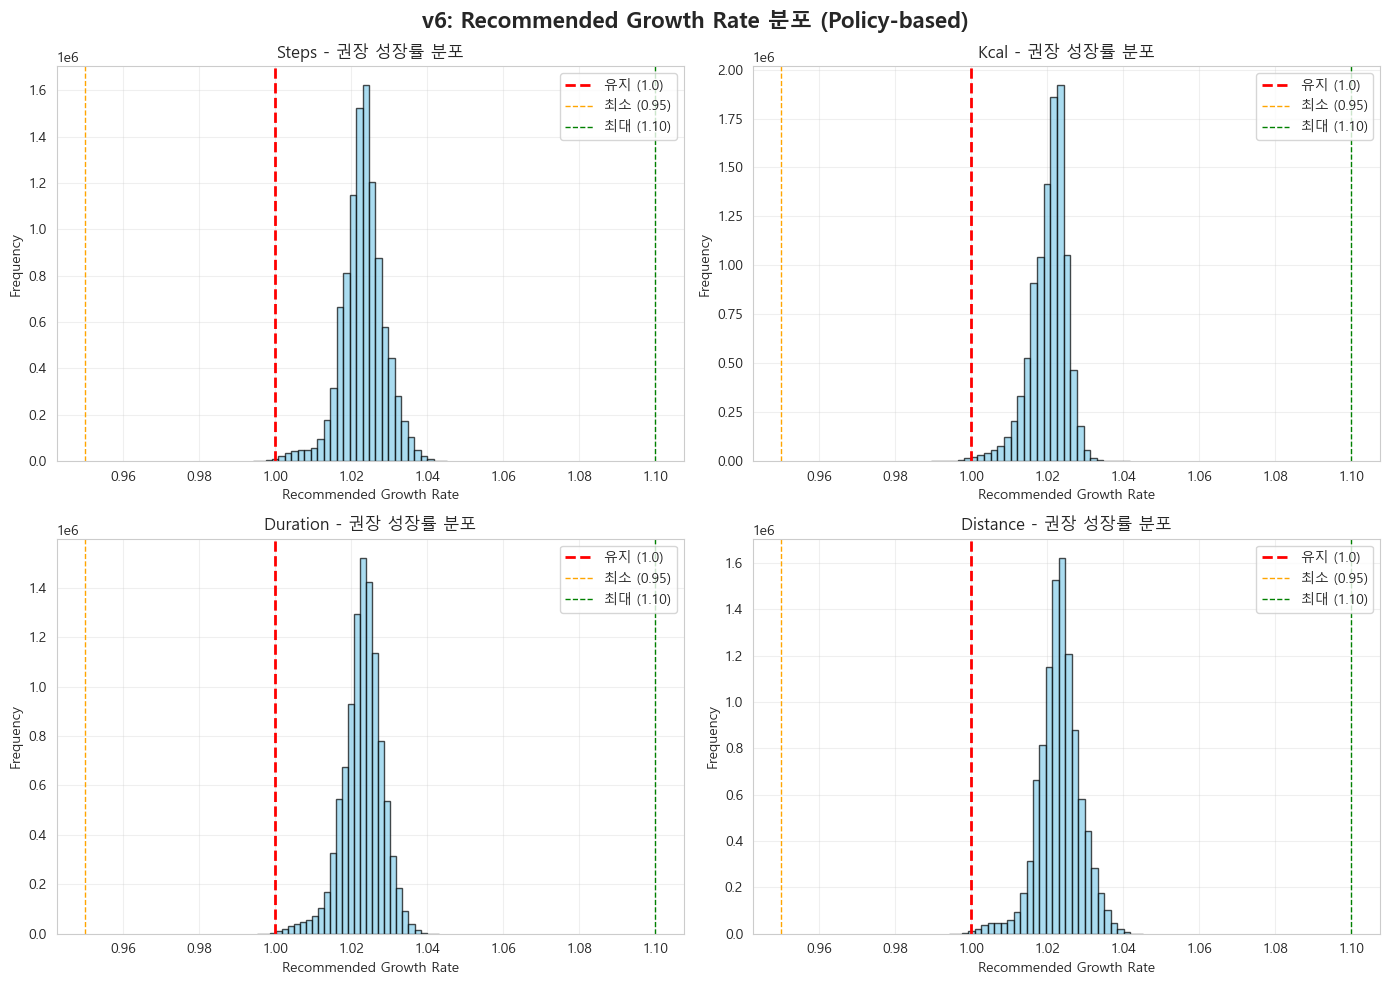

✅ 타겟 분포 시각화 저장: data/processed/target_distribution_v6.png


In [13]:
# 타겟 분포 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('v6: Recommended Growth Rate 분포 (Policy-based)', fontsize=16, fontweight='bold')

datasets = [
    ('Steps', training_steps),
    ('Kcal', training_kcal),
    ('Duration', training_duration),
    ('Distance', training_distance)
]

for idx, (name, df_viz) in enumerate(datasets):
    ax = axes[idx // 2, idx % 2]
    ax.hist(df_viz['recommended_growth_rate'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    ax.axvline(1.0, color='red', linestyle='--', linewidth=2, label='유지 (1.0)')
    ax.axvline(0.95, color='orange', linestyle='--', linewidth=1, label='최소 (0.95)')
    ax.axvline(1.10, color='green', linestyle='--', linewidth=1, label='최대 (1.10)')
    ax.set_xlabel('Recommended Growth Rate')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{name} - 권장 성장률 분포')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/target_distribution_v6.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ 타겟 분포 시각화 저장: data/processed/target_distribution_v6.png")

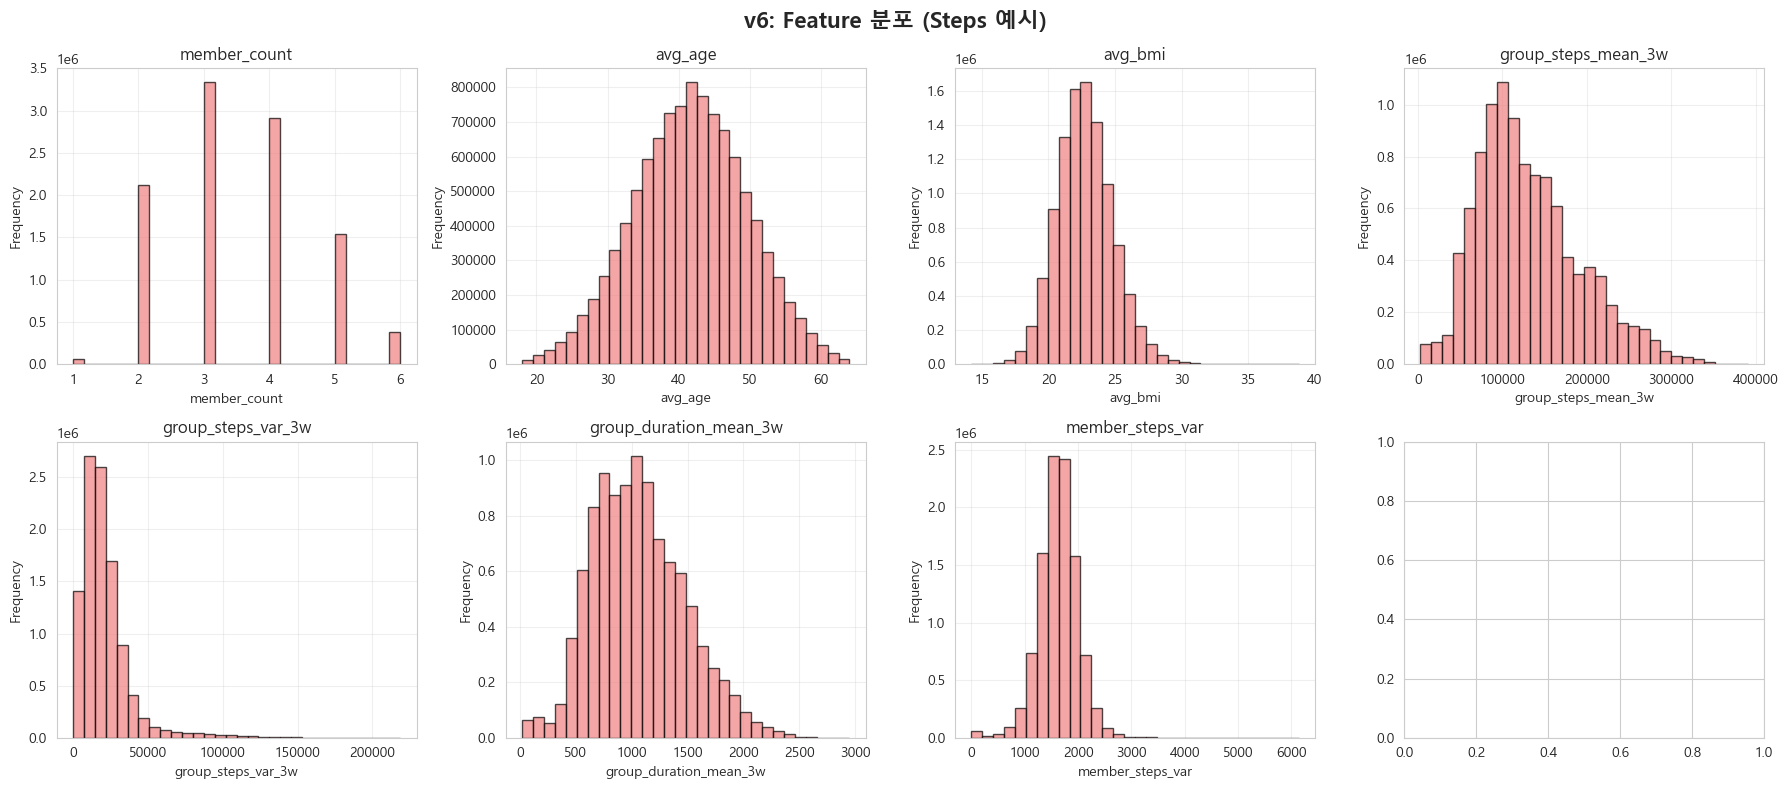

✅ Feature 분포 시각화 저장: data/processed/feature_distributions_v6.png


In [14]:
# Feature 분포 시각화 (Steps 예시)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('v6: Feature 분포 (Steps 예시)', fontsize=16, fontweight='bold')

for idx, col in enumerate(STEPS_FEATURES):
    ax = axes[idx // 4, idx % 4]
    ax.hist(training_steps[col], bins=30, color='lightcoral', edgecolor='black', alpha=0.7)
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.set_title(col)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/feature_distributions_v6.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Feature 분포 시각화 저장: data/processed/feature_distributions_v6.png")

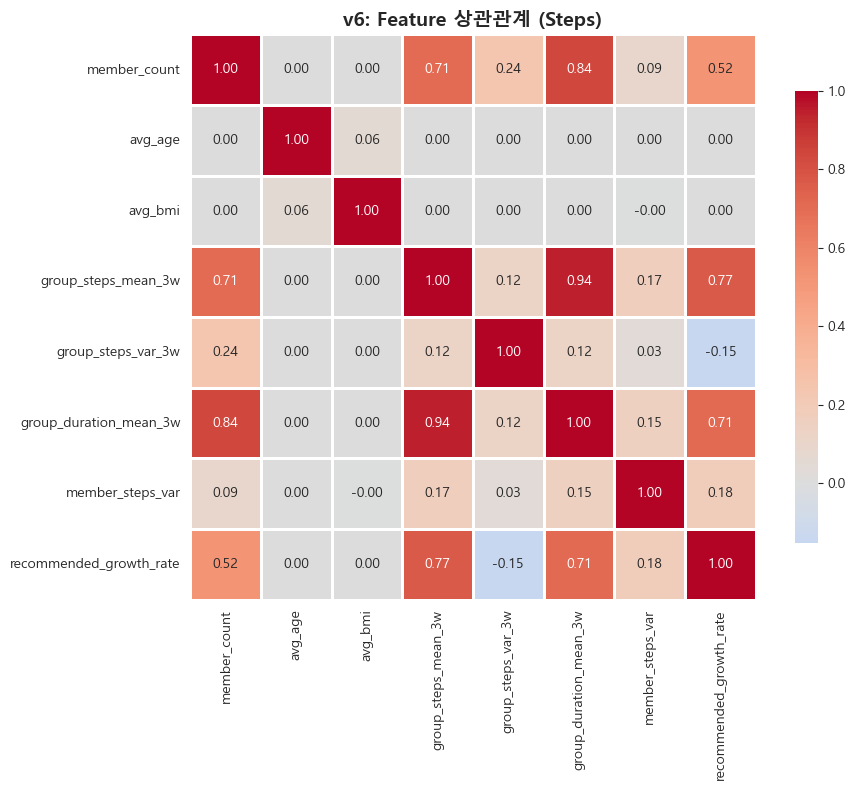

✅ 상관관계 시각화 저장: data/processed/correlation_matrix_v6.png


In [15]:
# 상관관계 분석 (Steps 예시)
plt.figure(figsize=(10, 8))
corr_matrix = training_steps.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('v6: Feature 상관관계 (Steps)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/correlation_matrix_v6.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ 상관관계 시각화 저장: data/processed/correlation_matrix_v6.png")

## 요약

### ✅ v6 Feature Engineering 완료

**핵심 변경 사항**:
- 7개 Feature (기존 12개 → 7개)
- 개인 추세 Feature 제거
- 3주 롤링 통계 추가
- Policy-based Target: `recommended_growth_rate` (0.95~1.10)

**출력 파일**:
1. `training_steps.csv` (8 columns)
2. `training_kcal.csv` (8 columns)
3. `training_duration.csv` (8 columns)
4. `training_distance.csv` (8 columns)

**다음 단계**: `03_model_training.ipynb`에서 4개 모델 학습